In [53]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/sudeeppattanshetty/tips-extended-analysis/tips - Extended Analysis.csv


In [54]:
import matplotlib.pyplot as plt

In [55]:
df = pd.read_csv("/kaggle/input/datasets/sudeeppattanshetty/tips-extended-analysis/tips - Extended Analysis.csv")
df

,Bill,Number_of_People,Arrived_in,Time_of_visit,Tips
0,16,2,bike,evening,2
1,63,2,bike,morning,4
2,10,1,auto,morning,1
3,140,4,bike,eve,22
4,100,3,car,afternoon,16
...,...,...,...,...,...
100,25,1,car,afternoon,4
101,116,5,bike,morning,12
102,220,1,bike,evening,2
103,80,1,car,morning,9


In [56]:
df.Arrived_in.value_counts()
# df.Time_of_visit.value_counts()

Arrived_in
bike    45
car     33
bus      7
auto     6
walk     6
jeep     5
0        1
Name: count, dtype: int64

In [57]:
df["Arrived_in"] = df["Arrived_in"].replace("0", "bike")

In [58]:
df.Arrived_in.value_counts()

Arrived_in
bike    46
car     33
bus      7
auto     6
walk     6
jeep     5
Name: count, dtype: int64

In [59]:
# Empty values are filled with the default value
df["Arrived_in_cleaned"] = df.Arrived_in.fillna('bike')

In [60]:
df.Arrived_in_cleaned.value_counts()

Arrived_in_cleaned
bike    48
car     33
bus      7
auto     6
walk     6
jeep     5
Name: count, dtype: int64

In [61]:
df = df[df['Time_of_visit'].notna()]

In [62]:
df.Time_of_visit.value_counts(dropna=False)

Time_of_visit
evening      36
afternoon    36
morning      29
eve           1
mor           1
Name: count, dtype: int64

In [63]:
df = df.copy()

In [64]:
df['Time_of_visit_cleaned'] = df.Time_of_visit.replace({
    'mor': 'morning',
    'eve': 'evening'
})

In [65]:
df.Time_of_visit_cleaned.value_counts(dropna=False)

Time_of_visit_cleaned
evening      37
afternoon    36
morning      30
Name: count, dtype: int64

In [66]:
df.Time_of_visit_cleaned.value_counts()

Time_of_visit_cleaned
evening      37
afternoon    36
morning      30
Name: count, dtype: int64

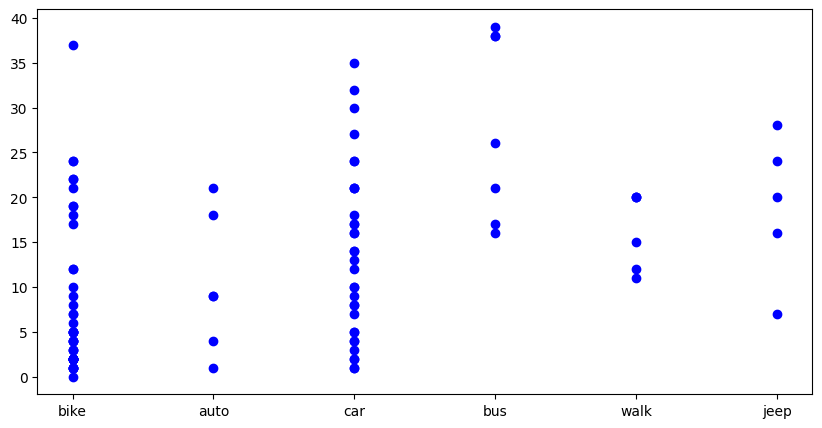

In [67]:
plt.figure(figsize=(10,5))
plt.plot(df.Arrived_in_cleaned, df.Tips, 'o', color='blue')

In [68]:
df = df.drop(['Arrived_in', 'Time_of_visit'], axis='columns')
df

,Bill,Number_of_People,Tips,Arrived_in_cleaned,Time_of_visit_cleaned
0,16,2,2,bike,evening
1,63,2,4,bike,morning
2,10,1,1,auto,morning
3,140,4,22,bike,evening
4,100,3,16,car,afternoon
...,...,...,...,...,...
100,25,1,4,car,afternoon
101,116,5,12,bike,morning
102,220,1,2,bike,evening
103,80,1,9,car,morning


## Data cleanup & Feature Engineering

In [69]:
# Dictionary for data cleaning
arrived_dict = {'walk': 0, 'bike': 1, 'car': 2, 'jeep': 3, 'bus': 4, 'auto': 5}
time_dict = {'morning': 0, 'afternoon': 2, 'evening': 3}

df['Arrived_in_cleaned'] = df['Arrived_in_cleaned'].map(lambda a: arrived_dict[a])
df['Time_of_visit_cleaned'] = df['Time_of_visit_cleaned'].map(lambda v: time_dict[v])

In [70]:
df.to_csv('/kaggle/working/tips_extended_cleaned.csv', index=False)